In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Dataset
I have used the `Predict Students' Dropout and Academic Success` for this project. I installed it from UCI Machine learning Repository website.

https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

This analysis uses the `Predict Students' Dropout and Academic Success` dataset from the UCI Machine Learning Repository (M.V.Martins, D. Tolledo, J. Machado, L. M.T. Baptista, V.Realinho. (2021); UCI Machine Learning Repository, n.d.). The dataset contains 4,424 students and 37 columns. 

In [2]:
df = pd.read_csv("data.csv", sep=";")

In [3]:
print(df.shape)

df.head()

(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

#### Data Understanding and Data Cleaning

In [5]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [6]:
df.describe(include='all')

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graduate
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2209
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969,NaN
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935,NaN
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000,NaN
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000,NaN
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000,NaN
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000,NaN


In [7]:
# display data type of each column
print(df.dtypes)

Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance\t                        int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Admission grade                                   float64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender        

In [8]:
df.columns

Index(['Marital status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance\t', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd

In [9]:
df.duplicated().sum()

0

In [10]:
df.isnull().sum()

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

#### The dataset contains:
Data contains information on 4424 student across 37 columns. Most of the columns `(36)` contain numerical data, while the remaining column is an object type `Target` variable. After checking the dataset, I found no duplicate records or missing values. 

In [11]:
# Count each target category 
target_counts = df['Target'].value_counts()
print(target_counts)

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [12]:
df['Target'].value_counts(normalize=True)*100

Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64

### Target category
The target column contains three different categories, and I calculated the percentage of students in each category. This target variable is the main focus of my further analysis.

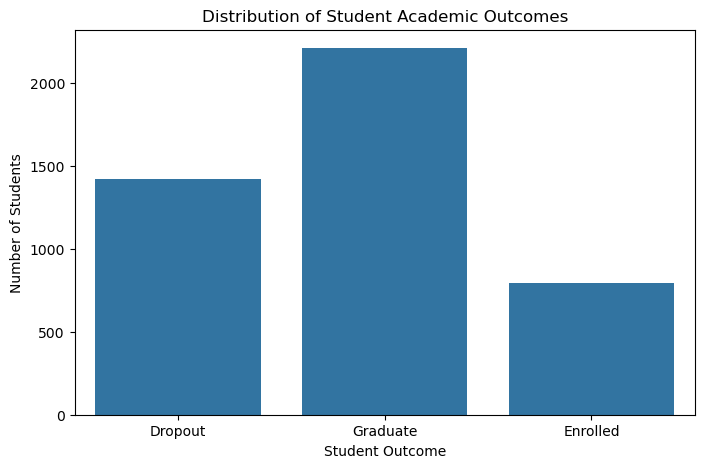

In [13]:
# Visualise student outcomes

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Target')

plt.title('Distribution of Student Academic Outcomes')
plt.xlabel('Student Outcome')
plt.ylabel('Number of Students')

plt.show()

### Distribution of Student Academic Outcomes
The graph shows the distribution of students across three academic outcomes. Most students successfully graduated, while around 1,400 students dropped out. The smallest group is students who are still enrolled. This graph helps me understand how the students are distributed across the three target categories.

#### Data pre-processing 

In [14]:
# separate features and target variable
X = df.drop('Target', axis=1)
y = df['Target']

print(X, y)

      Marital status  Application mode  Application order  Course  \
0                  1                17                  5     171   
1                  1                15                  1    9254   
2                  1                 1                  5    9070   
3                  1                17                  2    9773   
4                  2                39                  1    8014   
...              ...               ...                ...     ...   
4419               1                 1                  6    9773   
4420               1                 1                  2    9773   
4421               1                 1                  1    9500   
4422               1                 1                  1    9147   
4423               1                10                  1    9773   

      Daytime/evening attendance\t  Previous qualification  \
0                                1                       1   
1                                1             

In [15]:
# check unique target categories 
y.unique()

array(['Dropout', 'Graduate', 'Enrolled'], dtype=object)

In [16]:
# Check categorical columns

categorical_columns = X.select_dtypes(include=['object']).columns

print(categorical_columns)

Index([], dtype='object')


First, I divided the dataset into two parts, X and y. X contains 36 columns with information about the students, while y contains the Target column that I want to predict. I also checked the Target column and found three different categories: Dropout, Graduate and Enrolled.

#### Train-Test Split and Cross Validation

In [17]:
# import StandardScaler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

#### 5% Test Size

In [18]:
# Split dataset using 5% test data

X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(
    X,
    y,
    test_size=0.05,
    random_state=42,
    stratify=y
)

print("5% Training data:", X_train_5.shape)
print("5% Testing data:", X_test_5.shape)

5% Training data: (4202, 36)
5% Testing data: (222, 36)


I split the dataset into training and testing data. I used 95% of the data `(4202)` to train the model and 5% of the data `(222)` for testing.  

### 15% Test size

In [19]:
# split dataset using 15% test data 
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)
print("Training data:", X_train_15.shape)
print("Testing data:", X_test_15.shape)

Training data: (3760, 36)
Testing data: (664, 36)


I used 85% of the data `(3760)` to train the model and 15% of the data `(664)` for testing.  

### 25% Test size

In [20]:
# split dataset using 25% test data 
X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)
print("Training data:", X_train_25.shape)
print("Testing data:", X_test_25.shape)

Training data: (3318, 36)
Testing data: (1106, 36)


Here is also same split the data into training and testing. I used 75% of the data `(3318)` to train the model and 25% of the data `(1106)` for testing.  

In [21]:
# Initialize the Decision Tree Classifier
# Decision Tree - 5% Test Size
dt_classifier_5 = DecisionTreeClassifier(max_depth = 3, random_state=42)
dt_classifier_5.fit(X_train_5, y_train_5)
# Decision Tree - 15% Test Size
dt_classifier_15 = DecisionTreeClassifier(max_depth = 3, random_state=42)
dt_classifier_15.fit(X_train_15, y_train_15)
# Decision Tree - 25% Test Size
dt_classifier_25 = DecisionTreeClassifier(max_depth = 3, random_state=42)
dt_classifier_25.fit(X_train_25, y_train_25)

DecisionTreeClassifier(max_depth=3, random_state=42)

### Make Predictions

In [22]:
# Make predictions on 5% test data 
y_pred_5 = dt_classifier_5.predict(X_test_5)

# Display both actual and predicted values column-wise
result_df_5 = pd.DataFrame({'Actual': y_test_5.values, 'Predicted': y_pred_5})
print(result_df_5)

       Actual Predicted
0    Graduate  Graduate
1     Dropout   Dropout
2    Enrolled  Graduate
3    Graduate  Graduate
4    Graduate  Graduate
..        ...       ...
217  Graduate  Enrolled
218  Enrolled  Graduate
219  Graduate  Graduate
220   Dropout   Dropout
221  Graduate  Graduate

[222 rows x 2 columns]


In [23]:
# Make predictions on 15% test data 
y_pred_15 = dt_classifier_15.predict(X_test_15)

# Display both actual and predicted values column-wise
result_df_15 = pd.DataFrame({'Actual': y_test_15.values, 'Predicted': y_pred_15})
print(result_df_15)

       Actual Predicted
0    Graduate  Graduate
1    Graduate  Enrolled
2    Graduate  Graduate
3    Graduate  Graduate
4    Graduate  Graduate
..        ...       ...
659  Graduate  Graduate
660  Graduate  Graduate
661   Dropout   Dropout
662  Graduate  Graduate
663  Enrolled   Dropout

[664 rows x 2 columns]


In [24]:
# Make predictions on 25% test data 
y_pred_25 = dt_classifier_25.predict(X_test_25)

# Display both actual and predicted values column-wise
result_df_25 = pd.DataFrame({'Actual': y_test_25.values, 'Predicted': y_pred_25})
print(result_df_25)

        Actual Predicted
0     Graduate  Graduate
1      Dropout  Enrolled
2     Graduate  Graduate
3     Graduate  Graduate
4      Dropout  Graduate
...        ...       ...
1101  Graduate  Graduate
1102  Graduate  Graduate
1103  Graduate  Graduate
1104  Enrolled   Dropout
1105  Enrolled  Graduate

[1106 rows x 2 columns]


### After training the Decision tree model:
 I used it to make predictions on the test data. I then compared the predicted results with the actual student outcomes. The results show that some predictions were correct, while others were different from the actual values. This helped me see how well the model performed on the test data.

### Confusion Matrix

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [26]:
# Create confusion matrix for 5% test data

conf_matrix_5 = confusion_matrix(
    y_test_5,
    y_pred_5,
    labels=['Dropout', 'Enrolled', 'Graduate']
)

print(conf_matrix_5)

[[51 12  8]
 [ 4 18 18]
 [ 3 10 98]]


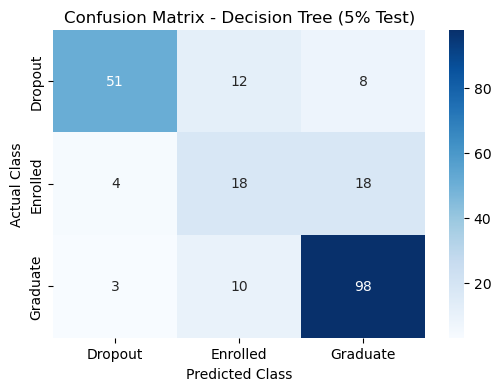

In [27]:
# Plot confusion matrix as a heatmap

plt.figure(figsize=(6, 4))

sns.heatmap(
    conf_matrix_5,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Dropout', 'Enrolled', 'Graduate'],
    yticklabels=['Dropout', 'Enrolled', 'Graduate']
)

plt.title('Confusion Matrix - Decision Tree (5% Test)')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

### Confusion Matrix - Decision Tree - 5%
I used a Confusion Matrix to compare the actual student outcomes with the model's predictions. The results show that the model correctly predicted 51 Dropout students, 18 Enrolled students and 98 Graduate students.
- Dropout: The model correctly identified 51 out of 71 students who dropped out.
- Enrolled: It correctly predicted 18 out of 40 students who are still studying.
- Graduate: The model performed best in this category, correctly identifying 98 out of 111 students who graduated.


In [28]:
# Create confusion matrix for 15% test data

conf_matrix_15 = confusion_matrix(
    y_test_15,
    y_pred_15,
    labels=['Dropout', 'Enrolled', 'Graduate']
)

print(conf_matrix_15)

[[144  39  30]
 [ 18  56  45]
 [ 13  29 290]]


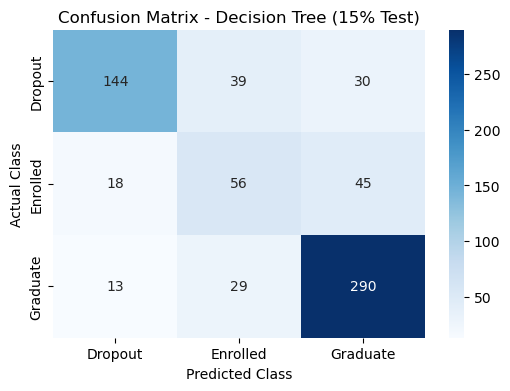

In [29]:
# Plot confusion matrix as a heatmap

plt.figure(figsize=(6, 4))

sns.heatmap(
    conf_matrix_15,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Dropout', 'Enrolled', 'Graduate'],
    yticklabels=['Dropout', 'Enrolled', 'Graduate']
)

plt.title('Confusion Matrix - Decision Tree (15% Test)')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

### Confusion Matrix - Decision Tree - 15% 
The results show that the model correctly predicted 144 Dropout students, 56 Enrolled students and 290 Graduate students.

- Dropout: The model correctly identified 144 out of 213 students who dropped out.

- Enrolled: It correctly predicted 56 out of 119 students who are still studying.

- Graduate: The model performed best in this category, correctly identifying 290 out of 332 students who graduated.

In [30]:
# Create confusion matrix for 25% test data

conf_matrix_25 = confusion_matrix(
    y_test_25,
    y_pred_25,
    labels=['Dropout', 'Enrolled', 'Graduate']
)

print(conf_matrix_25)

[[208  49  98]
 [ 27  50 122]
 [  3   7 542]]


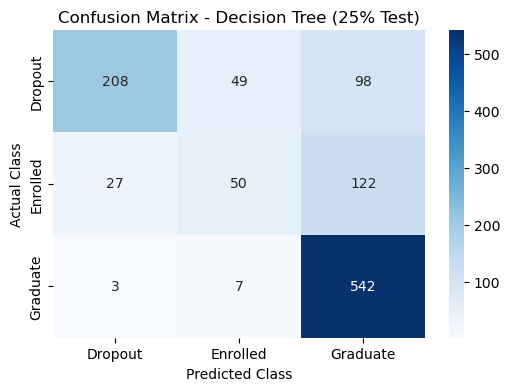

In [31]:
# Plot confusion matrix as a heatmap

plt.figure(figsize=(6, 4))

sns.heatmap(
    conf_matrix_25,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Dropout', 'Enrolled', 'Graduate'],
    yticklabels=['Dropout', 'Enrolled', 'Graduate']
)

plt.title('Confusion Matrix - Decision Tree (25% Test)')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

### Confusion Matrix - Decision Tree - 25%
The results show that the model correctly predicted 208 Dropout students, 50 Enrolled students and 542 Graduate students.

- Dropout: The model correctly identified 208 out of 355 students who dropped out.

- Enrolled: It correctly predicted 50 out of 199 students who are still studying.

- Graduate: The model performed best in this category, correctly identifying 542 out of 552 students who graduated.

### Classification Report

In [32]:
# Evaluate the model
from sklearn.metrics import classification_report
class_report_5 = classification_report(y_test_5, y_pred_5)

print("Classification Report - 5%:")
print(class_report_5)

Classification Report - 5%:
              precision    recall  f1-score   support

     Dropout       0.88      0.72      0.79        71
    Enrolled       0.45      0.45      0.45        40
    Graduate       0.79      0.88      0.83       111

    accuracy                           0.75       222
   macro avg       0.71      0.68      0.69       222
weighted avg       0.76      0.75      0.75       222



In [33]:
# Evaluate the model
from sklearn.metrics import classification_report
class_report_15 = classification_report(y_test_15, y_pred_15)

print("Classification Report - 15%:")
print(class_report_15)

Classification Report - 15%:
              precision    recall  f1-score   support

     Dropout       0.82      0.68      0.74       213
    Enrolled       0.45      0.47      0.46       119
    Graduate       0.79      0.87      0.83       332

    accuracy                           0.74       664
   macro avg       0.69      0.67      0.68       664
weighted avg       0.74      0.74      0.74       664



In [34]:
# Evaluate the model
from sklearn.metrics import classification_report
class_report_25 = classification_report(y_test_25, y_pred_25)

print("Classification Report - 25%:")
print(class_report_25)

Classification Report - 25%:
              precision    recall  f1-score   support

     Dropout       0.87      0.59      0.70       355
    Enrolled       0.47      0.25      0.33       199
    Graduate       0.71      0.98      0.82       552

    accuracy                           0.72      1106
   macro avg       0.69      0.61      0.62      1106
weighted avg       0.72      0.72      0.70      1106



### The above code showing:
The model performed best when predicting the `Graduate` category, and the results were quite consistent across all three tests. The model had difficulty identifying students in the `Enrolled` category. This was especially noticeable in the 25% test, where both Recall and F1-score dropped significantly.

Overall, the Decision Tree model gave reasonable results in predicting students' academic outcomes, but it did not perform equally well across all three categories. I think the model needs further improvement, especially when predicting students who are still enrolled.

### Decision Tree 

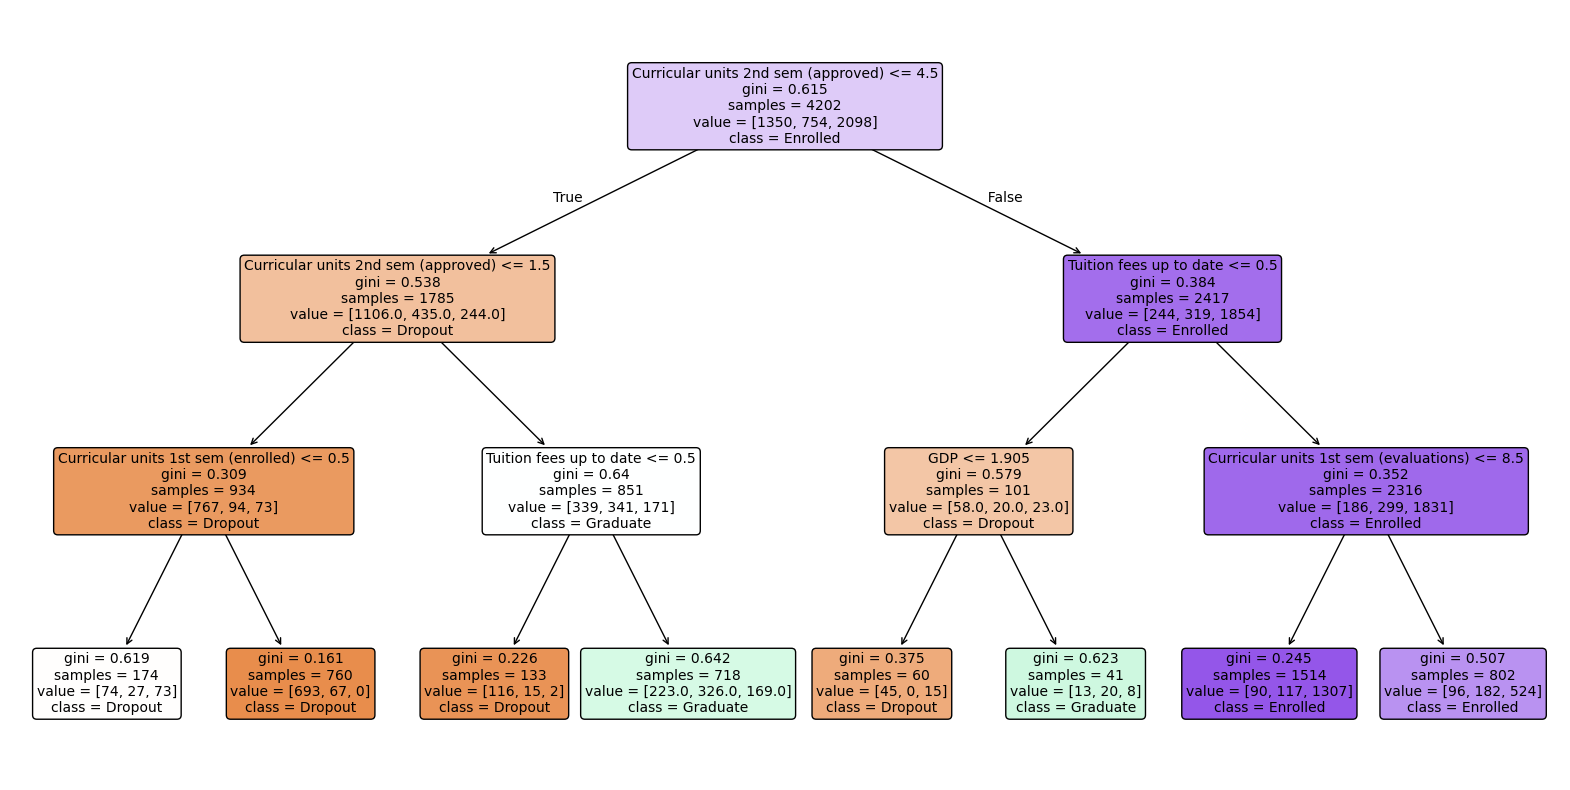

In [35]:
# Plot the Decision Tree - 5% test data 
plt.figure(figsize=(20, 10))
plot_tree(dt_classifier_5, filled=True, feature_names=X.columns.tolist(), class_names=df['Target'].unique().astype(str).tolist(), rounded=True, fontsize=10)
plt.show()

The Decision Tree shows how the model uses student information to predict their academic outcomes. It starts with the number of approved curricular units in the second semester, which is the first feature used to split the data.

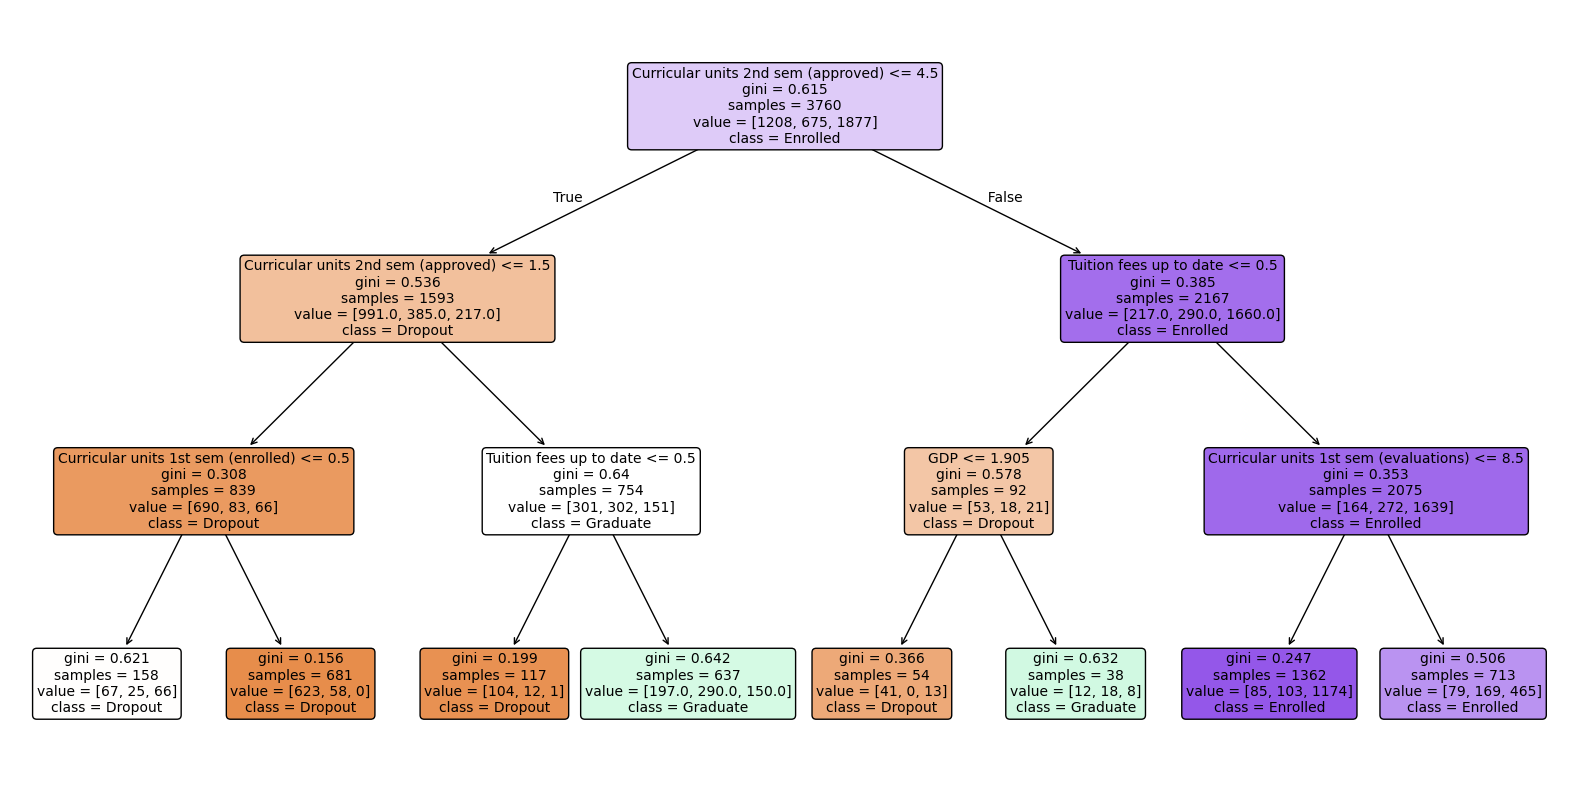

In [36]:
# Plot the Decision Tree - 15% test data 
plt.figure(figsize=(20, 10))
plot_tree(dt_classifier_15, filled=True, feature_names=X.columns.tolist(), class_names=df['Target'].unique().astype(str).tolist(), rounded=True, fontsize=10)
plt.show()

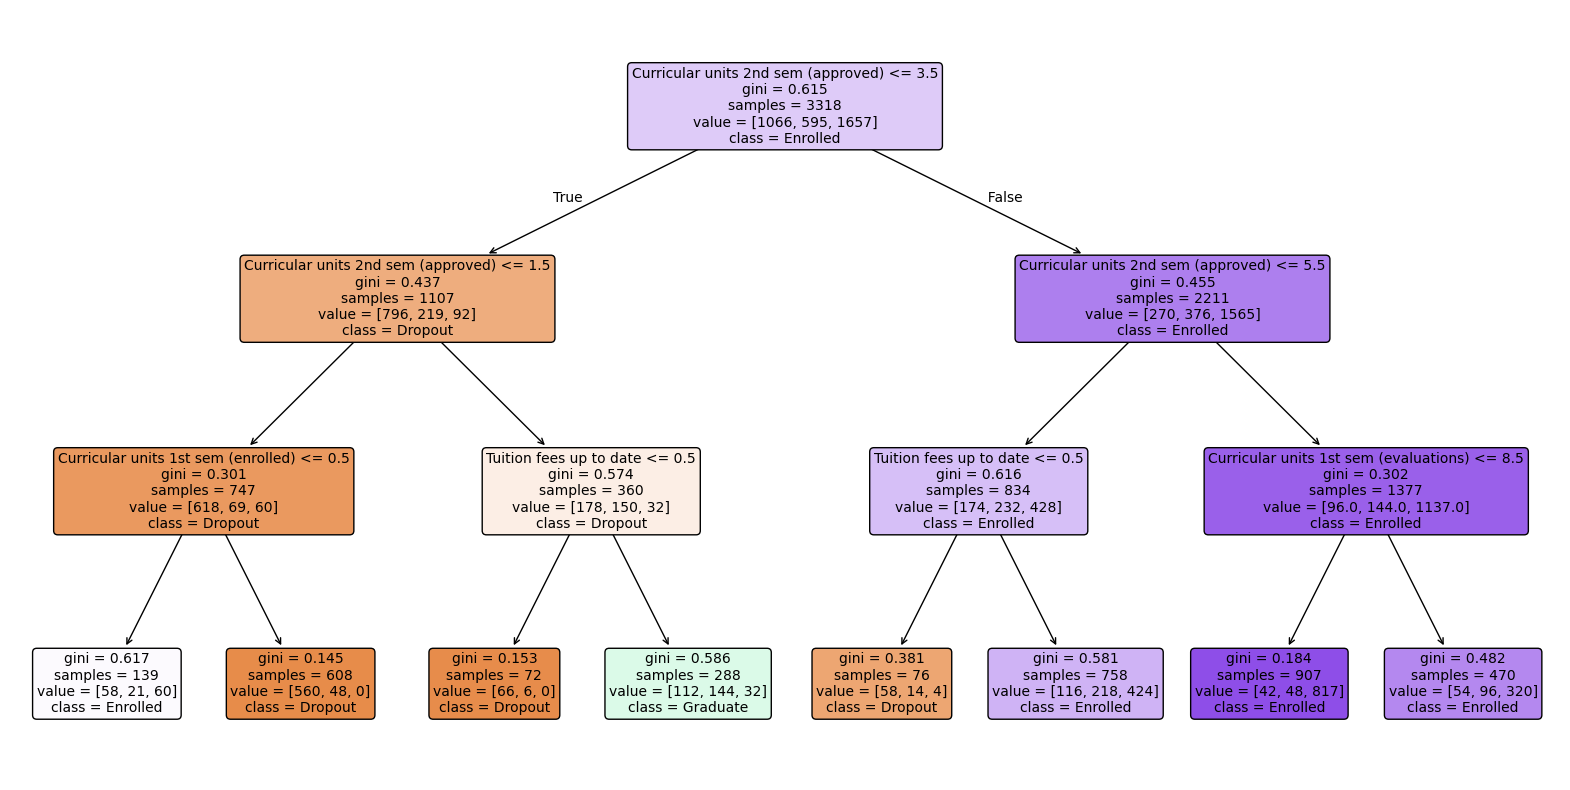

In [37]:
# Plot the Decision Tree - 25% test data 
plt.figure(figsize=(20, 10))
plot_tree(dt_classifier_25, filled=True, feature_names=X.columns.tolist(), class_names=df['Target'].unique().astype(str).tolist(), rounded=True, fontsize=10)
plt.show()

After comparing the three Decision Trees (5%, 15% and 25% test data), I noticed that all three models use the number of approved curricular units in the second semester as the first feature to make decisions.

The models also use other features, such as tuition fee payment status, first-semester enrolled units and evaluations. These features help the model to classify students into three groups: Dropout, Graduate and Enrolled.

### Model Evaluation

In [38]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [39]:
# Evaluate Decision Tree - 5% Test

accuracy_5 = accuracy_score(y_test_5, y_pred_5)
precision_5 = precision_score(
    y_test_5, y_pred_5,
    average='weighted',
    zero_division=0
)
recall_5 = recall_score(
    y_test_5, y_pred_5,
    average='weighted',
    zero_division=0
)

f1_5 = f1_score(
    y_test_5, y_pred_5,
    average='weighted',
    zero_division=0
)
# Display results

print("Decision Tree - 5% Test")
print("Accuracy:", round(accuracy_5, 2))
print("Precision:", round(precision_5, 2))
print("Recall:", round(recall_5, 2))
print("F1-score:", round(f1_5, 2))

Decision Tree - 5% Test
Accuracy: 0.75
Precision: 0.76
Recall: 0.75
F1-score: 0.75


In [40]:
# Evaluate Decision Tree - 15% Test

accuracy_15 = accuracy_score(y_test_15, y_pred_15)
precision_15 = precision_score(
    y_test_15, y_pred_15,
    average='weighted',
    zero_division=0
)
recall_15 = recall_score(
    y_test_15, y_pred_15,
    average='weighted',
    zero_division=0
)

f1_15 = f1_score(
    y_test_15, y_pred_15,
    average='weighted',
    zero_division=0
)
# Display results

print("Decision Tree - 15% Test")
print("Accuracy:", round(accuracy_15, 2))
print("Precision:", round(precision_15, 2))
print("Recall:", round(recall_15, 2))
print("F1-score:", round(f1_15, 2))

Decision Tree - 15% Test
Accuracy: 0.74
Precision: 0.74
Recall: 0.74
F1-score: 0.74


In [41]:
# Evaluate Decision Tree - 25% Test

accuracy_25 = accuracy_score(y_test_25, y_pred_25)
precision_25 = precision_score(
    y_test_25, y_pred_25,
    average='weighted',
    zero_division=0
)
recall_25 = recall_score(
    y_test_25, y_pred_25,
    average='weighted',
    zero_division=0
)

f1_25 = f1_score(
    y_test_25, y_pred_25,
    average='weighted',
    zero_division=0
)
# Display results

print("Decision Tree - 25% Test")
print("Accuracy:", round(accuracy_25, 2))
print("Precision:", round(precision_25, 2))
print("Recall:", round(recall_25, 2))
print("F1-score:", round(f1_25, 2))

Decision Tree - 25% Test
Accuracy: 0.72
Precision: 0.72
Recall: 0.72
F1-score: 0.7


### Model Evaluation 
- Accuracy: The model's overall correct predictions were 75% for the 5% test, 74% for the 15% test and 72% for the 25% test.

- Precision: The percentage of correct predictions made by the model decreased from 76% to 72%.

- Recall: The model's ability to correctly identify students in their actual categories decreased from 75% to 72%.

- F1-score: This shows the balance between Precision and Recall. It decreased from 0.75 in the 5% test to 0.70 in the 25% test.

### Cross validation - Decision Tree

In [42]:
# Cross Validation - 5% Test Split

dt_model_cv = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Apply 5-Fold Stratified Cross Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores_5 = cross_val_score(
    dt_model_cv,
    X_train_5,
    y_train_5,
    cv=cv,
    scoring='accuracy'
)

# Display results

print("Cross Validation Scores:", cv_scores_5)
print("Mean Accuracy:", round(np.mean(cv_scores_5), 4))
print("Standard Deviation:", round(np.std(cv_scores_5), 4))

Cross Validation Scores: [0.72413793 0.72175981 0.73333333 0.71666667 0.73809524]
Mean Accuracy: 0.7268
Standard Deviation: 0.0078


In [43]:
# Cross Validation - 15% Test Split

cv_scores_15 = cross_val_score(
    dt_model_cv,
    X_train_15,
    y_train_15,
    cv=cv,
    scoring='accuracy'
)

print("Cross Validation Scores:", cv_scores_15)
print("Mean Accuracy:", round(np.mean(cv_scores_15), 4))
print("Standard Deviation:", round(np.std(cv_scores_15), 4))

Cross Validation Scores: [0.73537234 0.75       0.7393617  0.71808511 0.72739362]
Mean Accuracy: 0.734
Standard Deviation: 0.0108


In [44]:
# Cross Validation - 25% Test Split

cv_scores_25 = cross_val_score(
    dt_model_cv,
    X_train_25,
    y_train_25,
    cv=cv,
    scoring='accuracy'
)

print("Cross Validation Scores:", cv_scores_25)
print("Mean Accuracy:", round(np.mean(cv_scores_25), 4))
print("Standard Deviation:", round(np.std(cv_scores_25), 4))

Cross Validation Scores: [0.72590361 0.74096386 0.76355422 0.70588235 0.73001508]
Mean Accuracy: 0.7333
Standard Deviation: 0.0189


### Machine learning 

- Model 1: Logistic Regression

In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [46]:
# Identify numerical features

numerical_columns = [
    col for col in X.columns
    if col not in categorical_columns
]

print("Numerical columns:")
print(numerical_columns)

Numerical columns:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']


In [47]:
# Prepare categorical and numerical features

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns),
        ('num', StandardScaler(), numerical_columns)
    ]
)

In [48]:
print("Categorical features:", len(categorical_columns))
print("Numerical features:", len(numerical_columns))
print("Total features:", len(X.columns))

Categorical features: 0
Numerical features: 36
Total features: 36


In [49]:
# Create Logistic Regression model

log_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [50]:
# Train Logistic Regression model

log_model.fit(X_train_5, y_train_5)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index([], dtype='object')),
                                                 ('num', StandardScaler(),
                                                  ['Marital status',
                                                   'Application mode',
                                                   'Application order',
                                                   'Course',
                                                   'Daytime/evening '
                                                   'attendance\t',
                                                   'Previous qualification',
                                                   'Previous qualification '
                                                   '(grade)',
                                                   'Nacionality',
                                                   "Mother's qualification"...
                                                   'Curricular units 1st sem '
                                                   '(enrolled)',
                                                   'Curricular units 1st sem '
                                                   '(evaluations)',
                                                   'Curricular units 1st sem '
                                                   '(approved)',
                                                   'Curricular units 1st sem '
                                                   '(grade)',
                                                   'Curricular units 1st sem '
                                                   '(without evaluations)',
                                                   'Curricular units 2nd sem '
                                                   '(credited)',
                                                   'Curricular units 2nd sem '
                                                   '(enrolled)',
                                                   'Curricular units 2nd sem '
                                                   '(evaluations)', ...])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [51]:
# Predict student outcomes

y_pred_log_5 = log_model.predict(X_test_5)

In [52]:
# Calculate model accuracy

log_accuracy_5 = accuracy_score(y_test_5, y_pred_log_5)

print("Logistic Regression - 5% Test")
print("Accuracy:", round(log_accuracy_5, 4))

Logistic Regression - 5% Test
Accuracy: 0.8063


In [53]:
# Display classification report

print(classification_report(y_test_5, y_pred_log_5))

              precision    recall  f1-score   support

     Dropout       0.89      0.83      0.86        71
    Enrolled       0.55      0.40      0.46        40
    Graduate       0.82      0.94      0.87       111

    accuracy                           0.81       222
   macro avg       0.75      0.72      0.73       222
weighted avg       0.79      0.81      0.80       222



In [54]:
# Check target class mapping

print(df['Target'].unique())

['Dropout' 'Graduate' 'Enrolled']


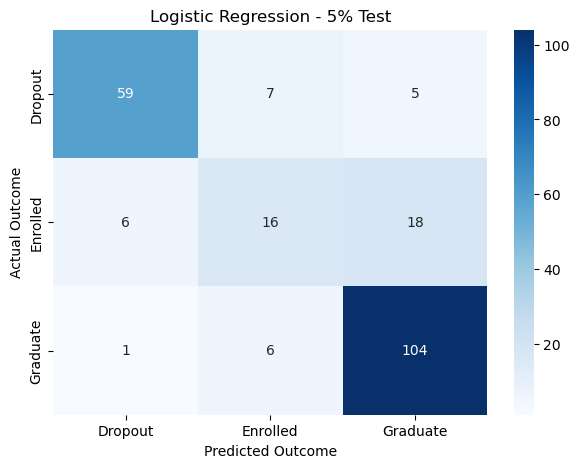

In [55]:
# Display confusion matrix with correct class names

labels = log_model.named_steps['classifier'].classes_

cm_log_5 = confusion_matrix(
    y_test_5,
    y_pred_log_5,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_log_5,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title('Logistic Regression - 5% Test')
plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')

plt.show()

In [56]:
# Train Logistic Regression model - 15% Test

log_model_15 = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

log_model_15.fit(X_train_15, y_train_15)

# Create Logistic Regression model - 25%

log_model_25 = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

log_model_25.fit(X_train_25, y_train_25)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index([], dtype='object')),
                                                 ('num', StandardScaler(),
                                                  ['Marital status',
                                                   'Application mode',
                                                   'Application order',
                                                   'Course',
                                                   'Daytime/evening '
                                                   'attendance\t',
                                                   'Previous qualification',
                                                   'Previous qualification '
                                                   '(grade)',
                                                   'Nacionality',
                                                   "Mother's qualification"...
                                                   'Curricular units 1st sem '
                                                   '(enrolled)',
                                                   'Curricular units 1st sem '
                                                   '(evaluations)',
                                                   'Curricular units 1st sem '
                                                   '(approved)',
                                                   'Curricular units 1st sem '
                                                   '(grade)',
                                                   'Curricular units 1st sem '
                                                   '(without evaluations)',
                                                   'Curricular units 2nd sem '
                                                   '(credited)',
                                                   'Curricular units 2nd sem '
                                                   '(enrolled)',
                                                   'Curricular units 2nd sem '
                                                   '(evaluations)', ...])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [57]:
# Predict student outcomes

y_pred_log_15 = log_model_15.predict(X_test_15)

y_pred_log_25 = log_model_25.predict(X_test_25)

In [58]:
# Calculate accuracy for 15% and 25% test splits

log_accuracy_15 = accuracy_score(y_test_15, y_pred_log_15)

log_accuracy_25 = accuracy_score(y_test_25, y_pred_log_25)

print("Logistic Regression - 15% Test")
print("Accuracy:", round(log_accuracy_15, 4))

print("Logistic Regression - 25% Test")
print("Accuracy:", round(log_accuracy_25, 4))

Logistic Regression - 15% Test
Accuracy: 0.7771
Logistic Regression - 25% Test
Accuracy: 0.7694


In [59]:
# Compare Logistic Regression results

log_results = pd.DataFrame({
    'Test Split': ['5%', '15%', '25%'],
    'Accuracy': [
        log_accuracy_5,
        log_accuracy_15,
        log_accuracy_25
    ]
})

display(log_results)

,Test Split,Accuracy
0,5%,0.806306
1,15%,0.777108
2,25%,0.769439


### Cross Validation - Logistic regression

In [60]:
# Create Stratified K-Fold Cross Validation

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified K-Fold is ready!")

Stratified K-Fold is ready!


In [61]:
# Perform 5-Fold Cross-validation
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv_scores_log_5 = cross_val_score(
    log_model,
    X_train_5,
    y_train_5,
    cv=skf,
    scoring='accuracy'
)

print("Logistic Regression - 5% Test")
print("Fold Scores:", cv_scores_log_5)
print("Mean Accuracy:", round(cv_scores_log_5.mean(), 4))
print("Standard Deviation:", round(cv_scores_log_5.std(), 4))

Logistic Regression - 5% Test
Fold Scores: [0.76456599 0.75980975 0.77380952 0.75238095 0.75833333]
Mean Accuracy: 0.7618
Standard Deviation: 0.0072


In [62]:
cv_scores_log_15 = cross_val_score(
    log_model_15,
    X_train_15,
    y_train_15,
    cv=skf,
    scoring='accuracy'
)

print("Logistic Regression - 15% Test")
print("Fold Scores:", cv_scores_log_15)
print("Mean Accuracy:", round(cv_scores_log_15.mean(), 4))
print("Standard Deviation:", round(cv_scores_log_15.std(), 4))

Logistic Regression - 15% Test
Fold Scores: [0.75398936 0.77260638 0.77526596 0.74734043 0.75398936]
Mean Accuracy: 0.7606
Standard Deviation: 0.0112


In [63]:
cv_scores_log_25 = cross_val_score(
    log_model_25,
    X_train_25,
    y_train_25,
    cv=skf,
    scoring='accuracy'
)

print("Logistic Regression - 25% Test")
print("Fold Scores:", cv_scores_log_25)
print("Mean Accuracy:", round(cv_scores_log_25.mean(), 4))
print("Standard Deviation:", round(cv_scores_log_25.std(), 4))

Logistic Regression - 25% Test
Fold Scores: [0.76807229 0.74548193 0.78614458 0.76319759 0.76470588]
Mean Accuracy: 0.7655
Standard Deviation: 0.013


In [64]:
# Compare cross-validation results

log_cv_results = pd.DataFrame({
    'Test Split': ['5%', '15%', '25%'],

    'Mean Accuracy': [
        cv_scores_log_5.mean(),
        cv_scores_log_15.mean(),
        cv_scores_log_25.mean()
    ],

    'Standard Deviation': [
        cv_scores_log_5.std(),
        cv_scores_log_15.std(),
        cv_scores_log_25.std()
    ]
})

display(log_cv_results)

,Test Split,Mean Accuracy,Standard Deviation
0,5%,0.761780,0.007163
1,15%,0.760638,0.011158
2,25%,0.765520,0.012957


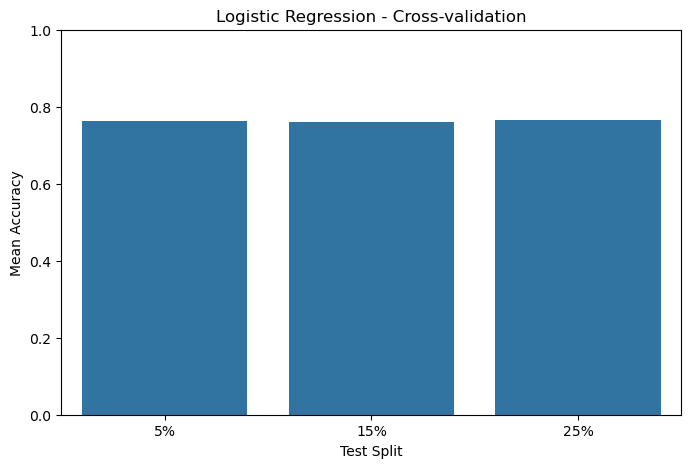

In [65]:
# Visualise cross-validation results

plt.figure(figsize=(8, 5))

sns.barplot(
    data=log_cv_results,
    x='Test Split',
    y='Mean Accuracy'
)

plt.title('Logistic Regression - Cross-validation')
plt.xlabel('Test Split')
plt.ylabel('Mean Accuracy')

plt.ylim(0, 1)
plt.show()

### Decision Tree vs Logistic Regression

In [66]:
# Compare model accuracy

comparison = pd.DataFrame({
    'Test Split': ['5%', '15%', '25%'],
    'Decision Tree': [accuracy_5, accuracy_15, accuracy_25],
    'Logistic Regression': [
        log_accuracy_5,
        log_accuracy_15,
        log_accuracy_25
    ]
})

display(comparison)

,Test Split,Decision Tree,Logistic Regression
0,5%,0.752252,0.806306
1,15%,0.737952,0.777108
2,25%,0.723327,0.769439


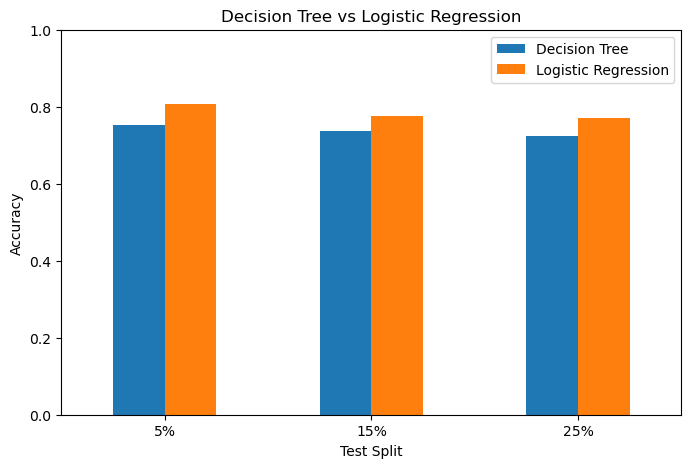

In [67]:
# Visualise model comparison

comparison.plot(
    x='Test Split',
    kind='bar',
    figsize=(8, 5)
)

plt.title('Decision Tree vs Logistic Regression')
plt.ylabel('Accuracy')
plt.xlabel('Test Split')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

In [68]:
# Compare cross-validation mean accuracy

cv_comparison = pd.DataFrame({
    'Test Split': ['5%', '15%', '25%'],
    'Decision Tree': [
        cv_scores_5.mean(),
        cv_scores_15.mean(),
        cv_scores_25.mean()
    ],
    'Logistic Regression': [
        cv_scores_log_5.mean(),
        cv_scores_log_15.mean(),
        cv_scores_log_25.mean()
    ]
})

display(cv_comparison)

,Test Split,Decision Tree,Logistic Regression
0,5%,0.726799,0.761780
1,15%,0.734043,0.760638
2,25%,0.733264,0.765520


### Hyperparameter Tuning - Decision Tree

In [69]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=skf,
    scoring='accuracy'
)

grid_search.fit(X_train_15, y_train_15)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [3, 5, 10, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [70]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", round(grid_search.best_score_, 4))

Best Parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10}
Best CV Accuracy: 0.7511


In [71]:
best_dt_model = grid_search.best_estimator_
y_pred_tuned = best_dt_model.predict(X_test_15)

print("Tuned Decision Tree Accuracy:",
      round(accuracy_score(y_test_15, y_pred_tuned), 4))

Tuned Decision Tree Accuracy: 0.7545


In [72]:
param_grid_log = {
    'classifier__C': [0.01, 0.1, 1, 10]
}

grid_search_log = GridSearchCV(
    log_model_15,
    param_grid_log,
    cv=skf,
    scoring='accuracy'
)

grid_search_log.fit(X_train_15, y_train_15)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         Index([], dtype='object')),
                                                                        ('num',
                                                                         StandardScaler(),
                                                                         ['Marital '
                                                                          'status',
                                                                          'Application '
                                                                          'mode',
                                                                          'Application '
                                                                          'order',
                                                                          'Course',
                                                                          'Daytime/evening '
                                                                          'attendance\t',
                                                                          'Prev...
                                                                          '(approved)',
                                                                          'Curricular '
                                                                          'units '
                                                                          '1st '
                                                                          'sem '
                                                                          '(grade)',
                                                                          'Curricular '
                                                                          'units '
                                                                          '1st '
                                                                          'sem '
                                                                          '(without '
                                                                          'evaluations)',
                                                                          'Curricular '
                                                                          'units '
                                                                          '2nd '
                                                                          'sem '
                                                                          '(credited)',
                                                                          'Curricular '
                                                                          'units '
                                                                          '2nd '
                                                                          'sem '
                                                                          '(enrolled)',
                                                                          'Curricular '
                                                                          'units '
                                                                          '2nd '
                                                                          'sem '
                                                                          '(evaluations)', ...])])),
                                       ('classifier',
                                        LogisticRegression(max_iter=1000))]),
             param_grid={'classifier__C': [0.01, 0.1, 1, 10]},
             scoring='accuracy')

In [73]:
print("Best Parameters:", grid_search_log.best_params_)
print("Best CV Accuracy:", round(grid_search_log.best_score_, 4))

Best Parameters: {'classifier__C': 0.1}
Best CV Accuracy: 0.7646


In [74]:
best_log_model = grid_search_log.best_estimator_
y_pred_log_tuned = best_log_model.predict(X_test_15)

print("Tuned Logistic Regression Accuracy:",
      round(accuracy_score(y_test_15, y_pred_log_tuned), 4))

Tuned Logistic Regression Accuracy: 0.7801


In [75]:
print("Decision Tree:", round(best_dt_model.score(X_train_15, y_train_15), 4))
print("Logistic Regression:", round(best_log_model.score(X_train_15, y_train_15), 4))

Decision Tree: 0.7726
Logistic Regression: 0.7737


In [76]:
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Logistic Regression'],
    'Training Accuracy': [
        best_dt_model.score(X_train_15, y_train_15),
        best_log_model.score(X_train_15, y_train_15)
    ],
    'CV Accuracy': [
        grid_search.best_score_,
        grid_search_log.best_score_
    ],
    'Test Accuracy': [
        accuracy_score(y_test_15, best_dt_model.predict(X_test_15)),
        accuracy_score(y_test_15, y_pred_log_tuned)
    ]
})

display(comparison.round(4))

,Model,Training Accuracy,CV Accuracy,Test Accuracy
0,Decision Tree,0.7726,0.7511,0.7545
1,Logistic Regression,0.7737,0.7646,0.7801
